# Data preparation: one dataset with every model input (G3)

This notebook turns the cleaned hourly table of the EDA into the dataset for the day-ahead SARIMAX forecast of G3.

| Step | Output | Where |
|---|---|---|
| Join and clean the four sources, all decisions on the raw data | `data/processed/hourly_dataset.csv` | `combined/combined_eda.ipynb` (README section 2) |
| **Features known the day before, model inputs, leakage test, periods** | **`data/processed/modeling_dataset.csv`** | **this notebook** (README section 3) |
| Identification, model selection on 2024, final model | parameters in `data/processed/models/` | `03_modeling.ipynb` (README section 4) |
| Test year 2025, used once | | `04_evaluation.ipynb` (README section 5) |

**The rule for every input:** a value for an hour of day D may only use what is known at the end of day D-1: forecasts made the day before, the calendar and the position of the sun, and values measured on D-1 or earlier.

| Part | Content |
|---|---|
| **A** | Which radiation can be used when? |
| **B** | Features: P1 position of the sun, P2 why one factor per month is not enough, the features of the day before |
| **C** | Model inputs and P3 leakage test |
| **D** | Periods, missing values, save |

Every question ends with **Finding → Consequence**. Reusable code: `src/data_preparation.py`. Figures: `figures/modeling/`. Run time: under a minute.

*Developed with AI assistance (Claude).*

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "..")   # project root, for src/
from src import data_preparation as dp
from src.plot_style import BLUE, DARK_GREY, GREY, ORANGE, save_figure   # one style for all notebooks

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", None)
TZ = dp.TZ

hourly = dp.load_hourly()
print(f"{len(hourly):,} hours × {hourly.shape[1]} columns, {hourly.index[0]:%d.%m.%Y} to {hourly.index[-1]:%d.%m.%Y %H:%M} (fixed CET)")

61,368 hours × 24 columns, 01.01.2019 to 31.12.2025 23:00 (fixed CET)


# Part A · Which radiation can be used when?

The model converts a radiation forecast into a capacity factor. Archived day-ahead forecasts (ICON-D2, Open-Meteo) only exist from **20 January 2024** (EDA, `open_meteo_eda.ipynb`). For 2019–2023 only the *measured* radiation exists. With the forecast alone, the model could only learn from one year (2024), the weak point noted at the end of the EDA.

**Decision:** for training, the measured radiation of 2019–2023 is a **stand-in for the forecast**; from 20.1.2024 on, the real forecast is used. The combined column is `radiation_input`. Both are weighted by the PV capacity closest to each station (EDA Part A). The stand-in is never used to score a forecast: validation (2024) and test (2025) only use real forecasts. Whether the longer training period pays off is checked in the evaluation (the same model trained on 2024 only).

In [2]:
pd.DataFrame({
    "radiation_input": ["measured (`radiation_weighted`)", "measured", "forecast made the day before", "forecast made the day before"],
    "role": ["training", "observed, only updates the model state", "validation: choose the model", "test: used once at the end"],
}, index=[f"{name}: {a[:10]} to {b[:10]}" for name, (a, b) in dp.PERIODS.items()])

,radiation_input,role
training: 2019-01-01 to 2023-12-31,measured (`radiation_weighted`),training
warm-up: 2024-01-01 to 2024-01-19,measured,"observed, only updates the model state"
validation: 2024-01-20 to 2024-12-31,forecast made the day before,validation: choose the model
test: 2025-01-01 to 2025-12-31,forecast made the day before,test: used once at the end


# Part B · Features

## P1: Does the computed position of the sun fit the measured radiation?

The position of the sun is known years ahead (astronomy), so it can be used without leakage. `sun_position` computes, for every hour, the **sine of the sun's elevation** in the middle of the hour at the centre of the four Lucerne stations, and the radiation of a **cloudless sky** (*clear sky*, Haurwitz model). Check: on the clearest day of a month, the measured curve should lie just below the clear-sky curve and peak at the same hour.

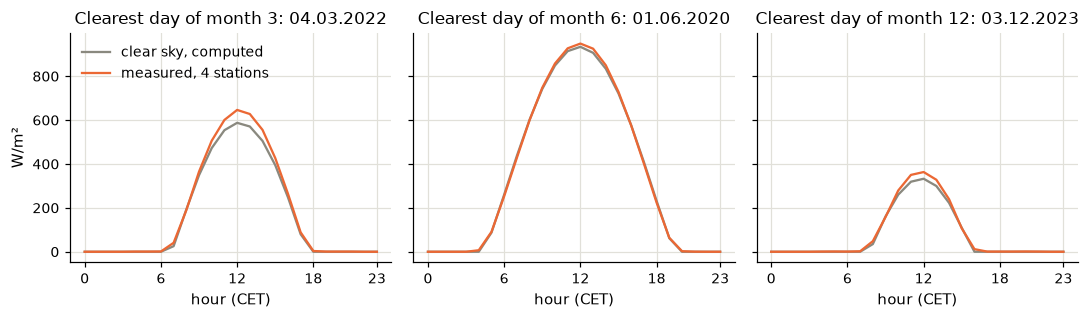

,"peak hour, computed","peak hour, measured","measured / clear sky, daily sum","hours of daylight, computed"
04.03.2022,12.0,12.0,1.09,11.0
01.06.2020,12.0,12.0,1.01,15.0
03.12.2023,12.0,12.0,1.09,9.0


In [3]:
features = dp.add_features(hourly)
history = features.loc["2019":"2023"]
clearness = history["radiation_weighted"].resample("D").sum() / history["clear_sky"].resample("D").sum()

fig, axes = plt.subplots(1, 3, figsize=(10, 3), sharey=True)
rows = {}
for ax, month in zip(axes, [3, 6, 12]):
    best = clearness[clearness.index.month == month].idxmax()
    d = history.loc[best.strftime("%Y-%m-%d")]
    ax.plot(d.index.hour, d["clear_sky"], color=DARK_GREY, label="clear sky, computed")
    ax.plot(d.index.hour, d["radiation_weighted"], color=ORANGE, label="measured, 4 stations")
    ax.set_title(f"Clearest day of month {month}: {best:%d.%m.%Y}")
    ax.set_xlabel("hour (CET)")
    ax.set_xticks([0, 6, 12, 18, 23])
    rows[f"{best:%d.%m.%Y}"] = {"peak hour, computed": d["clear_sky"].idxmax().hour,
                                "peak hour, measured": d["radiation_weighted"].idxmax().hour,
                                "measured / clear sky, daily sum": d["radiation_weighted"].sum() / d["clear_sky"].sum(),
                                "hours of daylight, computed": int((d["clear_sky"] > 0).sum())}
axes[0].set_ylabel("W/m²")
axes[0].legend(loc="upper left")
plt.tight_layout()
save_figure(fig, "sun_position_check", phase="modeling")
plt.show()
pd.DataFrame(rows).T.round(2)

> **Finding:** on the clearest day of March, June and December, the computed and the measured radiation peak at the **same hour (12:00 CET)**, and the computed daylight lasts 11, 15 and 9 hours. On these days the measured daily sum is 1–9 % **above** the simple clear-sky model (Haurwitz slightly underestimates very clear days), which is fine for an input whose coefficient is estimated.
>
> **Consequence:** the position of the sun and the clear-sky radiation are correct in time and shape and are used as features.

## P2: Why is "radiation × one factor per month" not enough?

Reference (b) of G3 converts radiation into capacity factor with one factor per month (EDA Q17). The EDA suggested that a better conversion (hour of the day, season) is where the model has to gain. Here: the **conversion factor** (capacity factor per kW/m² of measured radiation) per month and hour, 2019–2023, daylight hours above 50 W/m².

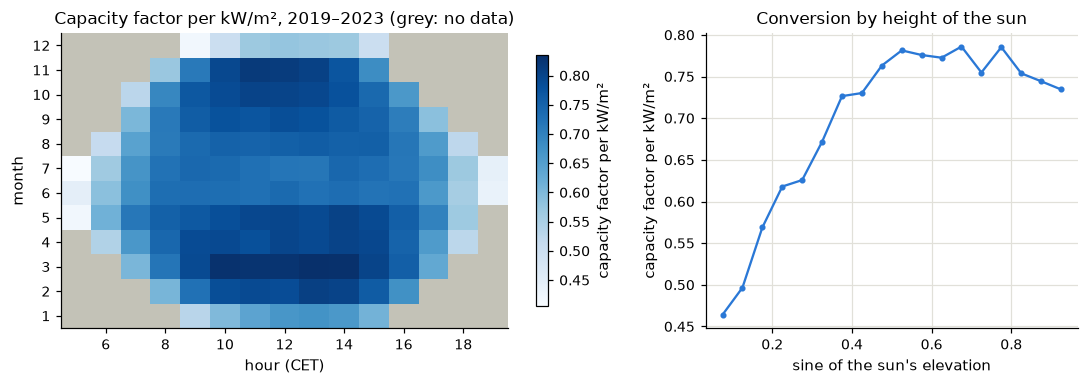

Factor at 12:00 per month: {1: 0.66, 2: 0.79, 3: 0.83, 4: 0.8, 5: 0.8, 6: 0.74, 7: 0.72, 8: 0.76, 9: 0.78, 10: 0.8, 11: 0.81, 12: 0.58}
Factor in June per hour: {5: 0.45, 6: 0.59, 7: 0.68, 8: 0.73, 9: 0.73, 10: 0.73, 11: 0.73, 12: 0.74, 13: 0.73, 14: 0.73, 15: 0.72, 16: 0.73, 17: 0.66, 18: 0.56, 19: 0.43}
Factor by elevation: 0.46 at the lowest, 0.79 at most


In [4]:
factor, by_elevation = dp.conversion_factor(history)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"width_ratios": [1.5, 1]})
im = axes[0].imshow(factor.values, aspect="auto", cmap="Blues", origin="lower",
                    extent=[factor.columns.min() - 0.5, factor.columns.max() + 0.5, 0.5, 12.5])
axes[0].set_xlabel("hour (CET)")
axes[0].set_ylabel("month")
axes[0].set_yticks(range(1, 13))
axes[0].grid(False)
axes[0].set_facecolor(GREY)   # grey: night, or fewer than 30 hours
axes[0].set_title("Capacity factor per kW/m², 2019–2023 (grey: no data)")
fig.colorbar(im, ax=axes[0], shrink=0.85, label="capacity factor per kW/m²")
axes[1].plot(by_elevation.index, by_elevation.values, color=BLUE, marker="o", markersize=3)
axes[1].set_xlabel("sine of the sun's elevation")
axes[1].set_ylabel("capacity factor per kW/m²")
axes[1].set_title("Conversion by height of the sun")
plt.tight_layout()
save_figure(fig, "conversion_factor", phase="modeling")
plt.show()
print("Factor at 12:00 per month:", factor[12].round(2).to_dict())
print("Factor in June per hour:", factor.loc[6].dropna().round(2).to_dict())
print(f"Factor by elevation: {by_elevation.iloc[0]:.2f} at the lowest, {by_elevation.max():.2f} at most")

> **Finding:** the conversion factor is **not constant within a month**. It depends on the **height of the sun**: per kW/m² of measured (horizontal) radiation, a low sun gives far less output (0.46 at the lowest elevations) than a high sun (about 0.78). In June the factor is 0.43–0.59 in the first and last hours and a flat 0.73 from 08:00 to 16:00. Over the year, the factor at noon is highest in March and November (0.81–0.83), a little lower in summer (0.72–0.74; warm modules are less efficient) and lowest in December and January (0.58–0.66: low sun, snow on the panels, fog).
>
> **Consequence:** one factor per month cannot follow the hours of the day. The model inputs (Part C) let the conversion depend on the height of the sun, the season and the radiation level. *Probable causes of the low-sun loss: shading by the horizon and buildings, a steep angle of the light on the panels (reflection), east- and west-facing roofs; not tested here.*

## The features

`add_features` adds calendar, sun and day-before features to the hourly table; `build_modeling_dataset` adds the radiation input, the target and the period. All of them are known at the end of the day before.

| Feature | Meaning | Known when? | Why |
|---|---|---|---|
| `sin_elevation` | sine of the sun's elevation in the middle of the hour (0 at night) | astronomy | conversion depends on the height of the sun (P2) |
| `clear_sky` | radiation of a cloudless sky, W/m² | astronomy | output that does not scale with the forecast radiation (diffuse light) |
| `season_cos`, `season_sin` | day of the year on a circle: cos/sin(2π · day / 365.25) | calendar | conversion depends on the season (P2) |
| `yday_production_index` | yesterday's mean capacity factor ÷ yesterday's mean clear sky (kW/m²) | measured on D-1 | how well sunlight was converted yesterday (snow on the panels, haze) |
| `yday_fog` | 1 if yesterday was a fog day: Pilatus more than twice as bright as Lucerne and at least 1.5 kWh/m² (EDA Q13) | measured on D-1 | fog lasts (53 % after a fog day, EDA Q14), and the forecast misses it (EDA Q16) |
| `yday_cold` | 1 if yesterday's mean temperature in Lucerne was below 1 °C (November to March) | measured on D-1 | snow on the panels lasts several days (EDA Q4) |
| `radiation_input` | radiation in W/m²: measured until 19.1.2024, forecast from 20.1.2024 (Part A) | forecast made the day before | main driver |
| `target` | capacity factor = Swiss solar MW ÷ installed MW, only while the sun is up (`clear_sky` > 0) | the value to forecast | night hours are not modelled: the forecast is 0 there |
| `period` | training, warm-up, validation or test (Part D) | calendar | keeps the test year out of every choice |

In [5]:
data = dp.build_modeling_dataset(hourly)
new = ["sin_elevation", "clear_sky", "season_cos", "season_sin", "yday_production_index", "yday_fog", "yday_cold", "radiation_input", "target"]
pd.DataFrame({"mean": data[new].mean(), "min": data[new].min(), "max": data[new].max(),
              "missing hours": data[new].isna().sum()}).round(3)

,mean,min,max,missing hours
sin_elevation,0.221,0.00,0.916,0
clear_sky,214.781,0.00,945.140,0
season_cos,0.000,-1.00,1.000,0
season_sin,0.000,-1.00,1.000,0
yday_production_index,0.468,0.02,0.988,288
yday_fog,0.085,0.00,1.000,24
yday_cold,0.079,0.00,1.000,24
radiation_input,143.687,0.00,981.342,0
target,0.211,0.00,0.710,30633


In [6]:
# One summer and one winter day, daylight hours only: how the features look
example = data.loc["2025-06-16 05:00":"2025-06-16 20:00", new[:5] + ["yday_fog", "radiation_input", "target"]].iloc[::3]
example.index = example.index.strftime("%d.%m. %H:%M")
example.round(3)

,sin_elevation,clear_sky,season_cos,season_sin,yday_production_index,yday_fog,radiation_input,target
time_local,,,,,,,,
16.06. 05:00,0.134,96.627,-0.964,0.266,0.433,0.0,11.976,0.019
16.06. 08:00,0.608,607.979,-0.964,0.266,0.433,0.0,143.971,0.222
16.06. 11:00,0.895,922.603,-0.964,0.266,0.433,0.0,521.437,0.507
16.06. 14:00,0.828,849.001,-0.964,0.266,0.433,0.0,583.669,0.481
16.06. 17:00,0.446,430.960,-0.964,0.266,0.433,0.0,301.247,0.223
16.06. 20:00,0.000,0.000,-0.964,0.266,0.433,0.0,2.565,NaN


> **Finding:** the sun features and the radiation input have no gaps. `yday_production_index` is missing on 288 hours (12 days): the first day of 2019 (no day before) and the day after each of the 11 error days of 2019 (yesterday's capacity factor is missing). `yday_fog` and `yday_cold` are only missing on the first day. `target` is empty on the 30,522 night hours and on the 111 daylight hours without a capacity factor (EDA Q1, Q5).
>
> **Consequence:** nothing is filled in. Hours with a missing input (120 daylight hours) get no target, so they are not used for fitting (`model_inputs` in `src/data_modeling.py`).

# Part C · Model inputs

SARIMAX is a linear regression with SARIMA errors (see `03_modeling.ipynb`). To let the conversion depend on the height of the sun and the season while staying linear, the features are **multiplied with the radiation input** $r$ (in kW/m², so that all coefficients have a similar size). Eleven inputs, all known at the end of the day before:

| Input | Formula | Why |
|---|---|---|
| `rad` | $r$ | main driver |
| `rad_elev` | $r \cdot \sin(\text{elevation})$ | conversion depends on the height of the sun (P2) |
| `rad_season_cos`, `rad_season_sin` | $r \cdot \cos/\sin(\text{season})$ | conversion depends on the season (snow, temperature, tilt) |
| `rad_squared` | $r^2$ | saturation at high radiation (heat, inverter limits) |
| `clear`, `clear_season_cos` | clear sky, also × $\cos(\text{season})$ | output that does not scale with $r$ (diffuse light, panels outside Lucerne) |
| `rad_yday_index` | $r \cdot$ `yday_production_index` | yesterday's conversion (snow, haze) |
| `rad_yday_fog`, `clear_yday_fog` | $r$ and clear sky × `yday_fog` | fog lasts and the forecast misses it |
| `rad_yday_cold` | $r \cdot$ `yday_cold` | snow on the panels lasts |

`03_modeling.ipynb` compares three sets on the validation year: **radiation only** (`rad`), **physics** (the first seven) and **physics + day before** (all eleven).

In [7]:
pd.DataFrame({"inputs": {name: ", ".join(columns) for name, columns in dp.FEATURE_SETS.items()},
              "number": {name: len(columns) for name, columns in dp.FEATURE_SETS.items()}})

,inputs,number
radiation only,rad,1
physics,"rad, rad_elev, rad_season_cos, rad_season_sin, rad_squared, clear, clear_season_cos",7
physics + day before,"rad, rad_elev, rad_season_cos, rad_season_sin, rad_squared, clear, clear_season_cos, rad_yday_index, rad_yday_fog, clear_yday_fog, rad_yday_cold",11


## P3: Leakage test. Do the inputs of day D really only use information up to the end of D-1?

Test: overwrite **every measured value of one day D** with random numbers and build the dataset again. The inputs of day D must not change; those of D+1 may (they use yesterday's values). The test day lies in the test year, where the radiation input is the forecast.

In [8]:
# everything measured on the day itself (target included); kept: forecasts made the day before and the installed capacity
measured = [c for c in hourly.columns if not (c.startswith("forecast_") or (c.startswith("capacity_") and c.endswith("_MW")))]
probe = "2025-06-15"
changed = hourly.copy()
rng = np.random.default_rng(0)
changed[measured] = changed[measured].astype(float)   # the two flags are true/false; make them numbers, too
changed.loc[probe, measured] = rng.uniform(0, 1000, size=changed.loc[probe, measured].shape)

inputs = list(dp.INPUTS)
before = dp.build_modeling_dataset(hourly)[inputs]
after = dp.build_modeling_dataset(changed)[inputs]
next_day = (pd.Timestamp(probe) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
same_day_equal = np.allclose(before.loc[probe].values, after.loc[probe].values, equal_nan=True)
next_day_equal = np.allclose(before.loc[next_day].values, after.loc[next_day].values, equal_nan=True)
print(f"Measured columns overwritten on {probe}: {len(measured)}")
print(f"Inputs of {probe} unchanged: {same_day_equal}  |  inputs of {next_day} unchanged: {next_day_equal}")
assert same_day_equal, "LEAKAGE: an input of day D uses a measured value of day D"
assert not next_day_equal, "the day-before signals do not react to the previous day"

Measured columns overwritten on 2025-06-15: 17
Inputs of 2025-06-15 unchanged: True  |  inputs of 2025-06-16 unchanged: False


> **Finding:** all 17 measured columns of 15.6.2025 (target included) were replaced by random numbers. The 11 inputs of that day stay **exactly the same**; the inputs of 16.6.2025 change, as they should (they use yesterday's values).
>
> **Consequence:** no leakage: every input of day D is known at the end of D-1. The assertions stop the notebook if this is ever broken. *For 2019–2023 the radiation input is measured on purpose (Part A); these hours are only used for training.*

# Part D · Periods and save

The time series is split by time, never at random: the model is chosen on 2024 and tested once on 2025.

In [9]:
counts = pd.DataFrame({
    name: {"from": a[:10], "to": b[:10], "hours": int((data["period"] == name).sum()),
           "with capacity factor": int(data.loc[data["period"] == name, "capacity_factor"].notna().sum()),
           "daylight hours with target": int(data.loc[data["period"] == name, "target"].notna().sum()),
           "with forecast": int(data.loc[data["period"] == name, "forecast_radiation"].notna().sum())}
    for name, (a, b) in dp.PERIODS.items()}).T
counts

,from,to,hours,with capacity factor,daylight hours with target,with forecast
training,2019-01-01,2023-12-31,43824,43558,21918,0
warm-up,2024-01-01,2024-01-19,456,456,171,9
validation,2024-01-20,2024-12-31,8328,8328,4242,8328
test,2025-01-01,2025-12-31,8760,8760,4404,8760


> **Finding:** 43,824 hours for training (21,918 daylight hours with a target), 456 hours of warm-up, 8,328 hours for validation and 8,760 for the test; validation and test have a radiation forecast for every hour. The final model is trained on 2019–2024 (training, warm-up and validation together).
>
> **Consequence:** the dataset is complete for the modeling. `03_modeling.ipynb` reads it from `data/processed/modeling_dataset.csv`.

In [10]:
data.to_csv(dp.MODELING_DATASET)
check = dp.load_modeling_dataset()
assert check.shape == data.shape and check.index.equals(data.index)
print(f"{data.shape[0]:,} hours × {data.shape[1]} columns → data/processed/modeling_dataset.csv")

61,368 hours × 45 columns → data/processed/modeling_dataset.csv


# Summary

| # | Finding | Consequence |
|---|---|---|
| A | Archived forecasts only from 20.1.2024 | measured radiation 2019–2023 as a stand-in for training; validation and test use real forecasts only |
| P1 | Computed position of the sun peaks at the same hour as the measured radiation | sun elevation and clear sky used as features |
| P2 | Output per kW/m² depends on the height of the sun (0.46 to 0.78) and the season | inputs = radiation × sun, × season, clear sky |
| Features | Day-before signals: yesterday's conversion, fog, cold | inputs `rad_yday_*`, `clear_yday_fog` |
| P3 | Leakage test passed | all inputs known the day before |
| D | Split by time: training 2019–2023, validation 2024, test 2025 | test year kept out of every choice |

## Decision log

| Decision | Error or characteristic? | Reason | Where |
|---|---|---|---|
| Measured radiation 2019–2023 as a stand-in for the forecast | characteristic (forecasts are archived only from 2024) | more training years; only used for training | Part A |
| Night hours not modelled, forecast = 0 | characteristic | the sun is below the horizon | features |
| Sun position and clear sky as features | – | the conversion depends on them (P2), known in advance | P1, P2 |
| Inputs = radiation × feature (linear) | – | SARIMAX is linear; the conversion can still follow the sun and the season | Part C |
| Missing inputs not filled | error (station outages, error days) | filling would invent values; these hours are not used for fitting | features |
| Split by time, not at random | – | a forecast must not learn from the future | Part D |